# K-Means Cluster Evaluation (Silhouette and Stability)

K-Means on synthetic blobs with unequal spreads, evaluated with silhouette analysis and the Davies-Bouldin index, plus a stability check across 8 random initializations.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.datasets import make_classification
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
from scipy.spatial import Voronoi, voronoi_plot_2d
from matplotlib.patches import Patch
from matplotlib import cm

In [3]:
def evaluate_clustering(X, labels, n_clusters, ax=None, title_suffix=''):
    """
    Evaluate a clustering model using silhouette scores and the Davies-Bouldin index.
    
    Parameters:
    X (ndarray): Feature matrix.
    labels (array-like): Cluster labels assigned to each sample.
    n_clusters (int): The number of clusters in the model.
    ax: The subplot axes to plot on.
    title_suffix (str): Optional suffix for plot titlec
    
    Returns:
    None: Displays silhoutte scores and a silhouette plot.
    """
    if ax is None:
        ax = plt.gca()  # Get the current axis if none is provided
    
    # Calculate silhouette scores
    silhouette_avg = silhouette_score(X, labels)
    sample_silhouette_values = silhouette_samples(X, labels)

    # Plot silhouette analysis on the provided axis
    unique_labels = np.unique(labels)
    colormap = cm.tab10
    color_dict = {label: colormap(float(label) / n_clusters) for label in unique_labels}
    y_lower = 10
    for i in unique_labels:
        ith_cluster_silhouette_values = sample_silhouette_values[labels == i]
        ith_cluster_silhouette_values.sort()
        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i
        color = color_dict[i]
        ax.fill_betweenx(np.arange(y_lower, y_upper),
                         0, ith_cluster_silhouette_values,
                         facecolor=color, edgecolor=color, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
        y_lower = y_upper + 10
    
    ax.set_title(f'Silhouette Score for {title_suffix} \n' + 
                 f'Average Silhouette: {silhouette_avg:.2f}')
    ax.set_xlabel('Silhouette Coefficient')
    ax.set_ylabel('Cluster')
    ax.axvline(x=silhouette_avg, color="red", linestyle="--")
    ax.set_xlim([-0.25, 1])  # Set the x-axis range to [0, 1]

    ax.set_yticks([])


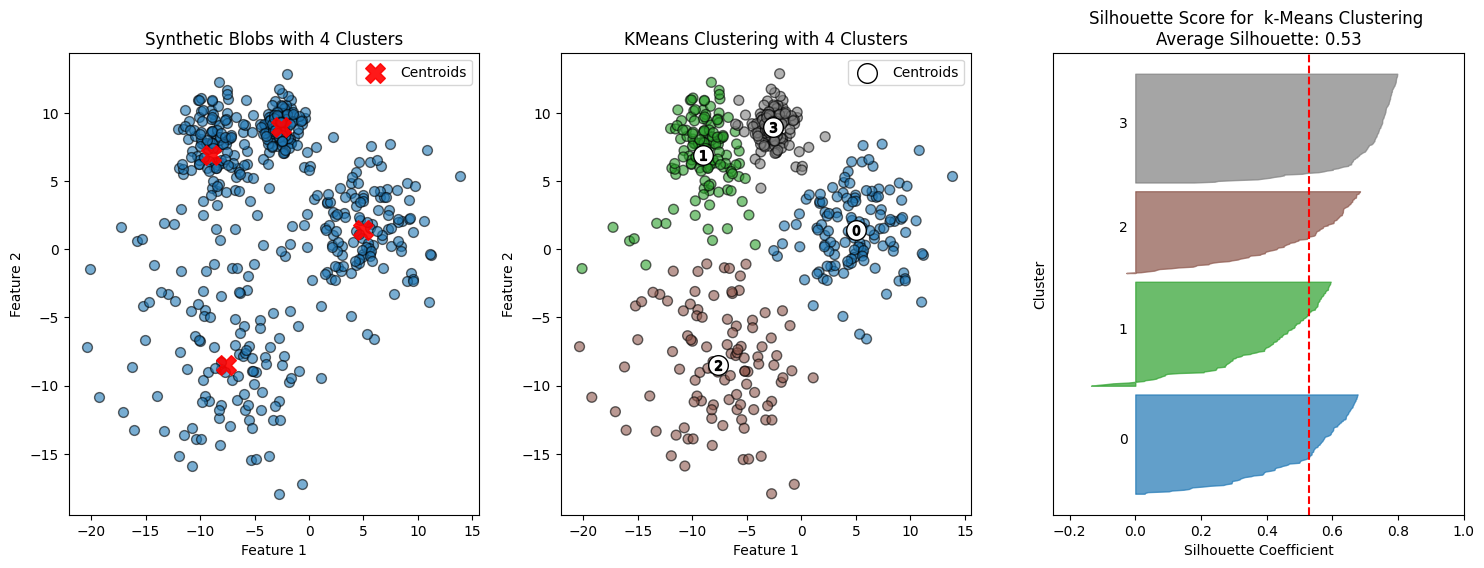

In [4]:
X, y = make_blobs(n_samples=500, n_features=2, centers=4, cluster_std=[1.0, 3, 5, 2], random_state=42)

# Apply KMeans clustering
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
y_kmeans = kmeans.fit_predict(X)

colormap = cm.tab10

# Plot the blobs
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.scatter(X[:, 0], X[:, 1], s=50, alpha=0.6, edgecolor='k')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X', alpha=0.9, label='Centroids')
plt.title(f'Synthetic Blobs with {n_clusters} Clusters')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()

# Plot the clustering result
# Create colors based on the predicted labels
colors = colormap(y_kmeans.astype(float) / n_clusters)

plt.subplot(1, 3, 2)
plt.scatter(X[:, 0], X[:, 1], c=colors, s=50, alpha=0.6, edgecolor='k')

# Label the clusters
centers = kmeans.cluster_centers_
# Draw white circles at cluster centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="o",
    c="white",
    alpha=1,
    s=200,
    edgecolor="k",
    label='Centroids'
)
# Label the custer number
for i, c in enumerate(centers):
    plt.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

plt.title(f'KMeans Clustering with {n_clusters} Clusters')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()

# Evaluate the clustering
plt.subplot(1, 3, 3)
evaluate_clustering(X, y_kmeans, n_clusters, title_suffix=' k-Means Clustering')
plt.show()

K-Means found the 4 clusters and placed the centroids almost exactly where the real ones are, but its boundaries fail where the clusters have very different spreads.

The centroids are correct. The K-Means centroids (middle panel) land almost on the true ones (red X's on the left): about (−9, 7), (−2.5, 9), (5, 1.5) and (−7.5, −8.5). The algorithm found the real centres of the groups.

The clusters differ a lot in spread.

The two clusters at the top are tight and very close to each other.
The one on the right has a medium spread.
The one at the bottom is very diffuse, with points from about −20 to 0 on Feature 1 and from −18 to 3 on Feature 2.
The boundaries are wrong for the diffuse cluster. K-Means assigns each point to the nearest centroid, which implicitly assumes round clusters of similar size. So the upper edge of the diffuse bottom cluster gets cut off:

Points around (−20, −1.5) and (−15, 1) are coloured green (cluster 1).
Others near (−3, 0) are coloured blue (cluster 0).
In the left panel those points clearly belong to the scattered group around the bottom centroid, but they are closer to another centroid.

Reading the silhouette plot
The silhouette coefficient of a point compares how close it is to its own cluster with how close it is to the nearest other cluster. It goes from −1 (wrong cluster) to 1 (clearly in the right cluster).

Cluster	Best values	Reading
3 (grey)	up to ~0.8	Best defined: tight and compact
0 (blue)	up to ~0.68	Well separated from the others
2 (brown)	up to ~0.65, a few at 0	Diffuse: many points sit far from its centre
1 (green)	up to ~0.6, tail down to −0.15	Weakest: some points are probably in the wrong cluster
Cluster 1 has negative values. Those points are on average closer to another cluster than to their own. They're the boundary points: some sit between green and the very close grey cluster (3), and others are the diffuse bottom-cluster points that K-Means gave to green.
The average silhouette of 0.53 means a reasonable structure. Values from 0.5 to 0.7 are usually read as clearly defined clusters with some overlap. It's not higher because of the two touching clusters at the top and the scattered one at the bottom.
Takeaway
K-Means is a good fit for the general structure: it finds the right number of groups and the right centres.
Its weakness is clusters with different shapes or spreads. It draws straight boundaries halfway between centroids, so a diffuse cluster loses its outer points to its neighbours.
Better options for this kind of data:
Gaussian Mixture Models, which learn a different spread for each cluster.
DBSCAN or HDBSCAN, which follow density and can also mark the scattered points as noise.
To check that k = 4 is the best choice, compare the average silhouette for k = 2 to 6. The k with the highest score is usually the one to pick.

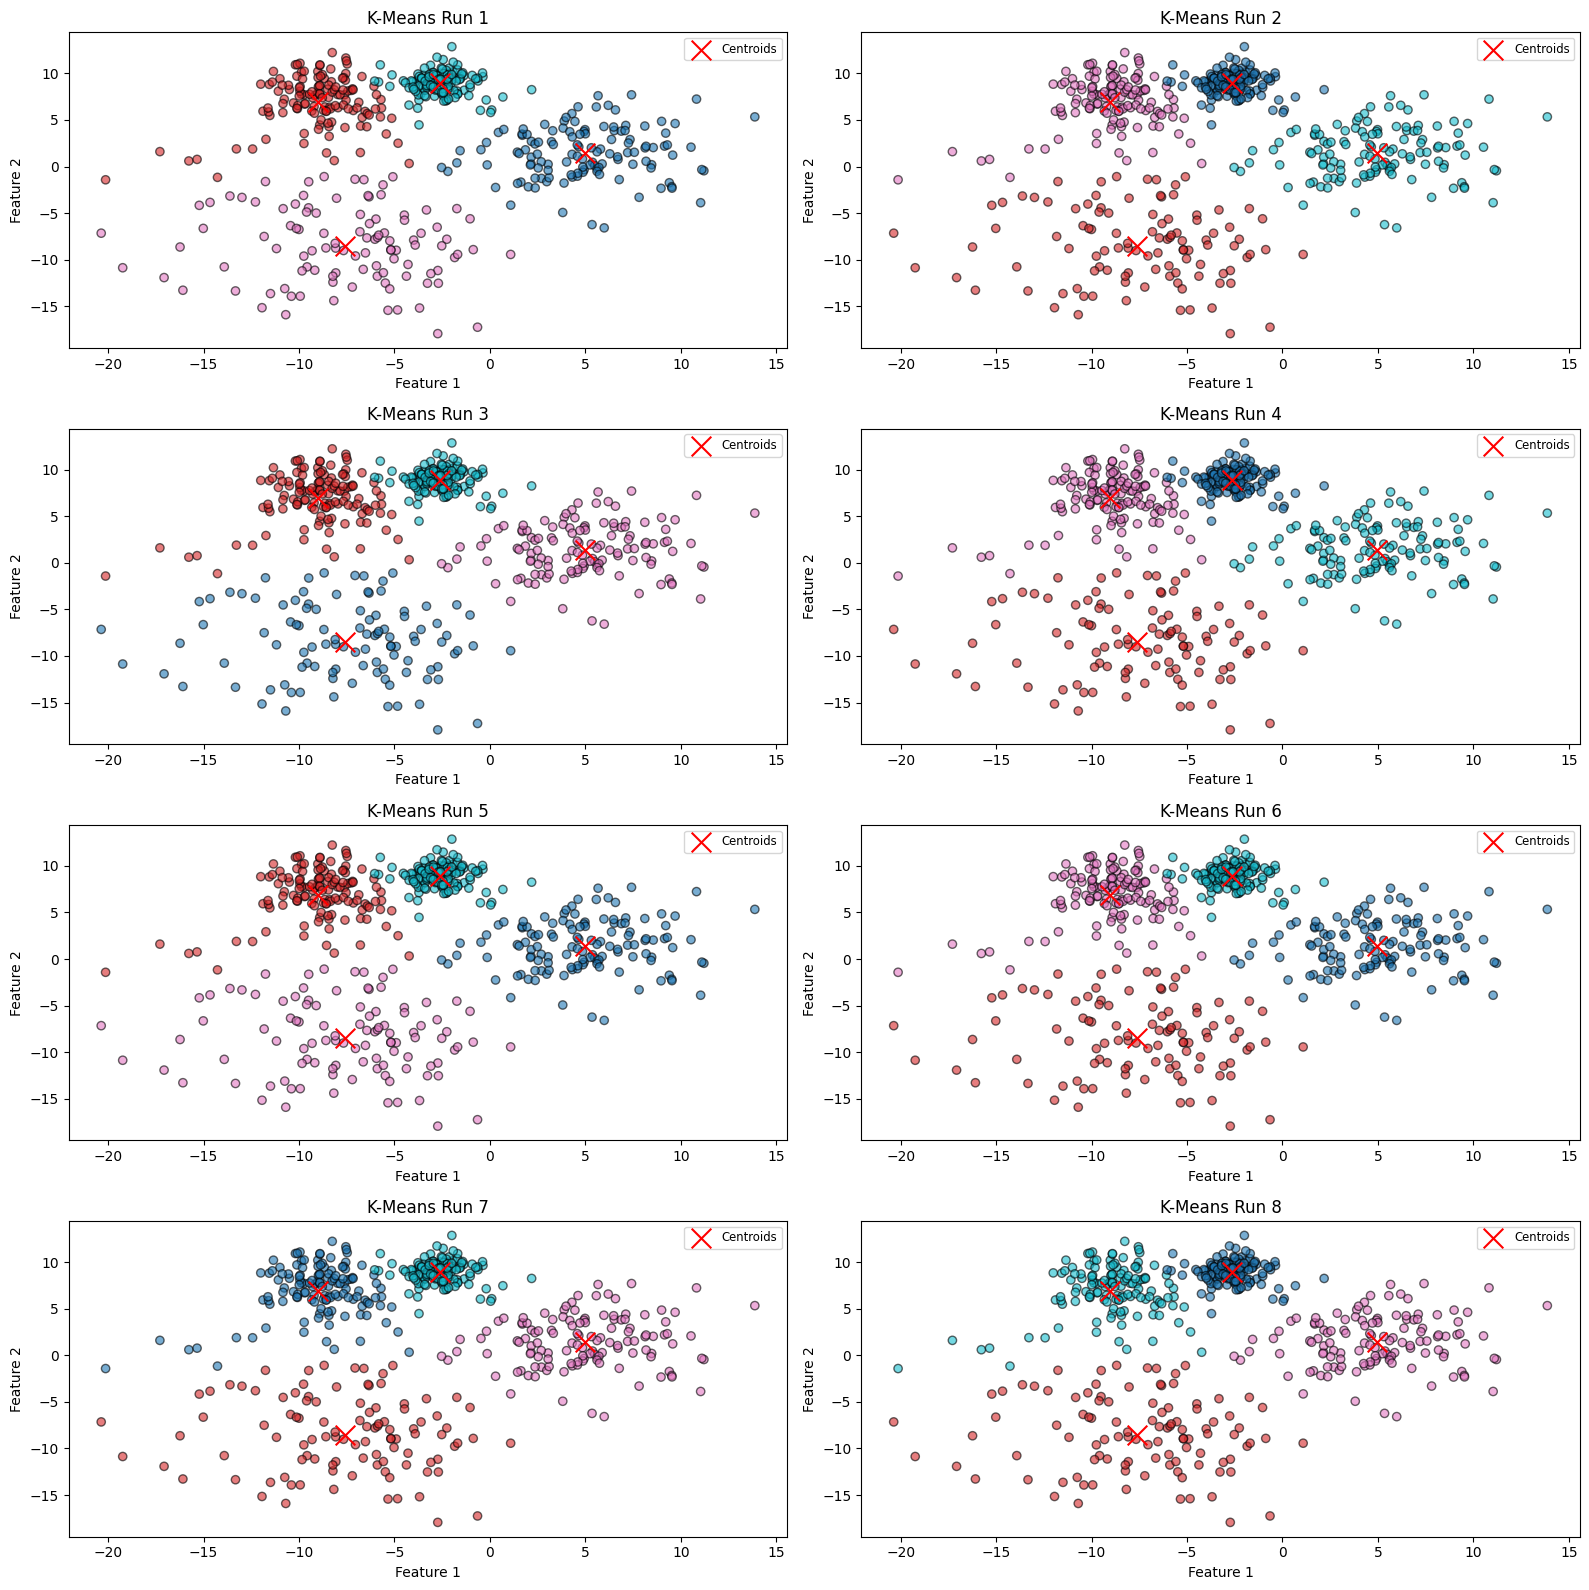

Run 1: Inertia=7633.51
Run 2: Inertia=7633.51
Run 3: Inertia=7633.51
Run 4: Inertia=7633.51
Run 5: Inertia=7633.51
Run 6: Inertia=7633.51
Run 7: Inertia=7633.51
Run 8: Inertia=7633.51


In [5]:
# Number of runs for k-means with different random states
n_runs = 8
inertia_values = []

# Calculate number of rows and columns needed for subplots
n_cols = 2 # Number of columns
n_rows = -(-n_runs // n_cols) # Ceil division to determine rows
plt.figure(figsize=(16, 16)) # Adjust the figure size for better visualization

# Run K-Means multiple times with different random states
for i in range(n_runs):
    kmeans = KMeans(n_clusters=4, random_state=None)  # Use the default `n_init`
    kmeans.fit(X)
    inertia_values.append(kmeans.inertia_)

    # Plot the clustering result
    plt.subplot(n_rows, n_cols, i + 1)
    plt.scatter(X[:, 0], X[:, 1], c=kmeans.labels_, cmap='tab10', alpha=0.6, edgecolor='k')
    plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', s=200, marker='x', label='Centroids')
    plt.title(f'K-Means Run {i + 1}')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.show()

# Print inertia values
for i, inertia in enumerate(inertia_values, start=1):
    print(f'Run {i}: Inertia={inertia:.2f}')

The centroids are the same in every run. The red X's always land at about (−9, 7), (−2.5, 9), (5, 1.5) and (−7.5, −8.5), regardless of the random start. The algorithm converges to the same minimum every time.
Only the label numbers change. The tight top-right cluster is cyan in run 1, dark blue in run 2 and cyan again in run 3. That's just label switching: K-Means numbers the clusters in arbitrary order, so "cluster 0" in one run can be "cluster 2" in another. The grouping itself is identical.
The point assignments are practically the same. Each cluster contains the same points across runs, including the boundary points between the two close clusters at the top.
The same error repeats in every run. The scattered points on the upper-left edge of the diffuse bottom cluster, for example around (−15, 1) and (−17, 2), are always assigned to the upper-left cluster. So this misassignment isn't bad luck from the initialization. It's a limitation of K-Means itself: it uses straight boundaries between centroids, which doesn't fit clusters with very different spreads (as seen in the silhouette plot).
Why it's so stable here
The 4 groups are clearly separated and each has a distinct centre, so wherever the initial centroids start, they slide to the same final positions. With data where clusters overlap more, or with more clusters, different starts can end in different local minima, with a worse split and higher inertia.